# MLT Assignment #3

Student: Aleksei Chekodanov, group J4133

Logistic Regression as a Neural Network (functions from the notebook "Logistic Regression as a Neural Network - BP alg") for the bioresponse dataset.
Optimization methods: GD, SGD and Adam.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split

### Data

In [2]:
bioresponse = pd.read_csv('bioresponse.csv')
print(bioresponse.shape)

y = bioresponse.Activity.values
X = bioresponse.iloc[:, 1:].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1)

# one column = one object, so transpose
X_train, X_test = X_train.T, X_test.T
Y_train, Y_test = y_train.reshape(1, -1), y_test.reshape(1, -1)

print('X_train:', X_train.shape, 'Y_train:', Y_train.shape)
print('X_test: ', X_test.shape, 'Y_test: ', Y_test.shape)

(3751, 1777)
X_train: (1776, 2813) Y_train: (1, 2813)
X_test:  (1776, 938) Y_test:  (1, 938)


### Functions from the notebook

I took the functions from the seminar notebook and changed a few things:
- initialize_with_zeros() in the notebook actually uses random weights from N(0, 1). With 1776 features the sum w*x becomes very big, sigmoid gives exactly 0 or 1 and the cost becomes inf. So here the weights are really zeros.
- in propagate() the probabilities are clipped a little bit, so we never get log(0)
- in optimize() the cost is saved on every iteration (for the curves) and the print condition is fixed (i % 100 instead of i // 100)
- predict() has the default threshold 0.5 (in model() it was called without it)

In [3]:
def sigmoid(z):
    s = 1. / (1. + np.exp(-z))
    return s


def initialize_with_zeros(dim):
    w = np.zeros((dim, 1))
    b = 0.
    return w, b


def propagate(w, b, X, Y):
    m = X.shape[1]

    # FORWARD PROPAGATION (FROM X TO COST)
    A = sigmoid(np.dot(w.T, X) + b)
    A = np.clip(A, 1e-10, 1 - 1e-10)  # to avoid log(0)
    cost = -(1. / m) * np.sum(Y * np.log(A) + (1 - Y) * np.log(1 - A))

    # BACKWARD PROPAGATION (TO FIND GRAD)
    dw = (1. / m) * np.dot(X, (A - Y).T)
    db = (1. / m) * np.sum(A - Y)

    grads = {"dw": dw, "db": db}
    return grads, cost


def predict(w, b, X, threshold=0.5):
    A = sigmoid(np.dot(w.T, X) + b)
    Y_prediction = (A > threshold).astype(float)
    return Y_prediction

### 1. Logistic regression with gradient descent (GD)

GD uses all training objects to calculate the gradient on each iteration.

In [4]:
def optimize(w, b, X, Y, num_iterations, learning_rate, print_cost=False):
    costs = []

    for i in range(num_iterations):
        grads, cost = propagate(w, b, X, Y)
        dw = grads["dw"]
        db = grads["db"]

        # update rule
        w = w - learning_rate * dw
        b = b - learning_rate * db

        costs.append(cost)
        if print_cost and i % 500 == 0:
            print(f"Cost after iteration {i}: {cost:.5f}")

    params = {"w": w, "b": b}
    return params, costs

`model()` is the same as in the notebook, but now it can use different optimizers (we need it for p.2 and p.3).
For GD `num_iterations` is the number of iterations, for SGD and Adam it is the number of epochs (passes through all the training data).

In [5]:
def model(X_train, Y_train, X_test, Y_test, optimizer='gd', num_iterations=2000, learning_rate=0.5, print_cost=False):
    np.random.seed(1)
    w, b = initialize_with_zeros(X_train.shape[0])

    if optimizer == 'gd':
        parameters, costs = optimize(w, b, X_train, Y_train, num_iterations, learning_rate, print_cost)
    elif optimizer == 'sgd':
        parameters, costs = optimize_sgd(w, b, X_train, Y_train, num_iterations, learning_rate, print_cost)
    elif optimizer == 'adam':
        parameters, costs = optimize_adam(w, b, X_train, Y_train, num_iterations, learning_rate, print_cost=print_cost)

    w = parameters["w"]
    b = parameters["b"]

    Y_prediction_test = predict(w, b, X_test)
    Y_prediction_train = predict(w, b, X_train)

    train_accuracy = 100 - np.mean(np.abs(Y_prediction_train - Y_train)) * 100
    test_accuracy = 100 - np.mean(np.abs(Y_prediction_test - Y_test)) * 100
    _, test_cost = propagate(w, b, X_test, Y_test)

    print(f"{optimizer}, lr = {learning_rate}: train accuracy: {train_accuracy:.2f}, test accuracy: {test_accuracy:.2f}")

    d = {"costs": costs,
         "w": w,
         "b": b,
         "train_accuracy": train_accuracy,
         "test_accuracy": test_accuracy,
         "test_cost": test_cost,
         "learning_rate": learning_rate,
         "num_iterations": num_iterations}
    return d

Learning rate 0.1 and 2000 iterations (the learning rate was chosen in p.5: with bigger values GD starts to oscillate).

In [6]:
d_gd = model(X_train, Y_train, X_test, Y_test, optimizer='gd', num_iterations=2000, learning_rate=0.1, print_cost=True)

Cost after iteration 0: 0.69315


Cost after iteration 500: 0.43161


Cost after iteration 1000: 0.40400


Cost after iteration 1500: 0.38826


gd, lr = 0.1: train accuracy: 84.18, test accuracy: 76.76


### 2. Stochastic gradient descent (SGD)

In SGD the gradient is calculated on one random object, and the weights are updated after every object. One epoch = all training objects in a random order, so one epoch has 2813 updates (for GD one epoch = one update). The cost on the whole training set is saved after every epoch.

In [7]:
def optimize_sgd(w, b, X, Y, num_epochs, learning_rate, print_cost=False):
    costs = []
    m = X.shape[1]

    for epoch in range(num_epochs):
        # random order of objects in every epoch
        for i in np.random.permutation(m):
            x_i = X[:, i:i+1]
            y_i = Y[:, i:i+1]
            grads, _ = propagate(w, b, x_i, y_i)

            w = w - learning_rate * grads["dw"]
            b = b - learning_rate * grads["db"]

        _, cost = propagate(w, b, X, Y)
        costs.append(cost)
        if print_cost and epoch % 10 == 0:
            print(f"Cost after epoch {epoch}: {cost:.5f}")

    params = {"w": w, "b": b}
    return params, costs

In [8]:
d_sgd = model(X_train, Y_train, X_test, Y_test, optimizer='sgd', num_iterations=100, learning_rate=0.001, print_cost=True)

Cost after epoch 0: 0.58604


Cost after epoch 10: 0.45151


Cost after epoch 20: 0.43499


Cost after epoch 30: 0.40971


Cost after epoch 40: 0.39969


Cost after epoch 50: 0.39056


Cost after epoch 60: 0.38389


Cost after epoch 70: 0.37880


Cost after epoch 80: 0.37730


Cost after epoch 90: 0.37024


sgd, lr = 0.001: train accuracy: 84.18, test accuracy: 76.65


### 3. Adam

Adam = Momentum + RMSprop. It keeps moving averages of the gradient (V) and of the squared gradient (S):

    V = beta1 * V + (1 - beta1) * dw
    S = beta2 * S + (1 - beta2) * dw^2

At the start V and S are near zero, so they are too small. Bias correction fixes it:

    V_hat = V / (1 - beta1^t)
    S_hat = S / (1 - beta2^t)

update:

    w = w - lr * V_hat / (sqrt(S_hat) + eps)

The same for b. Usual values: beta1 = 0.9, beta2 = 0.999, eps = 1e-8. Like in SGD the weights are updated after every object, so SGD and Adam differ only in the update rule.

In [9]:
def optimize_adam(w, b, X, Y, num_epochs, learning_rate, beta1=0.9, beta2=0.999, epsilon=1e-8, print_cost=False):
    costs = []
    m = X.shape[1]

    V_dw, S_dw = np.zeros_like(w), np.zeros_like(w)
    V_db, S_db = 0., 0.
    t = 0  # number of updates

    for epoch in range(num_epochs):
        for i in np.random.permutation(m):
            x_i = X[:, i:i+1]
            y_i = Y[:, i:i+1]
            grads, _ = propagate(w, b, x_i, y_i)
            dw, db = grads["dw"], grads["db"]
            t += 1

            # moving averages of grad and grad^2
            V_dw = beta1 * V_dw + (1 - beta1) * dw
            V_db = beta1 * V_db + (1 - beta1) * db
            S_dw = beta2 * S_dw + (1 - beta2) * dw ** 2
            S_db = beta2 * S_db + (1 - beta2) * db ** 2

            # bias correction
            V_dw_corr = V_dw / (1 - beta1 ** t)
            V_db_corr = V_db / (1 - beta1 ** t)
            S_dw_corr = S_dw / (1 - beta2 ** t)
            S_db_corr = S_db / (1 - beta2 ** t)

            w = w - learning_rate * V_dw_corr / (np.sqrt(S_dw_corr) + epsilon)
            b = b - learning_rate * V_db_corr / (np.sqrt(S_db_corr) + epsilon)

        _, cost = propagate(w, b, X, Y)
        costs.append(cost)
        if print_cost and epoch % 10 == 0:
            print(f"Cost after epoch {epoch}: {cost:.5f}")

    params = {"w": w, "b": b}
    return params, costs

In [10]:
d_adam = model(X_train, Y_train, X_test, Y_test, optimizer='adam', num_iterations=100, learning_rate=0.0001, print_cost=True)

Cost after epoch 0: 0.61686


Cost after epoch 10: 0.46311


Cost after epoch 20: 0.42682


Cost after epoch 30: 0.40003


Cost after epoch 40: 0.38536


Cost after epoch 50: 0.37250


Cost after epoch 60: 0.36378


Cost after epoch 70: 0.35418


Cost after epoch 80: 0.34791


Cost after epoch 90: 0.34176


adam, lr = 0.0001: train accuracy: 86.03, test accuracy: 76.76


Comparison of the three models:

In [11]:
results = pd.DataFrame({
    'GD (lr=0.1, 2000 iterations)': d_gd,
    'SGD (lr=0.001, 100 epochs)': d_sgd,
    'Adam (lr=0.0001, 100 epochs)': d_adam,
}).T
results['final train cost'] = [d['costs'][-1] for d in [d_gd, d_sgd, d_adam]]
results[['train_accuracy', 'test_accuracy', 'final train cost', 'test_cost']].astype(float).round(3)

,train_accuracy,test_accuracy,final train cost,test_cost
"GD (lr=0.1, 2000 iterations)",84.181,76.759,0.377,0.509
"SGD (lr=0.001, 100 epochs)",84.181,76.652,0.368,0.529
"Adam (lr=0.0001, 100 epochs)",86.029,76.759,0.337,0.520


### 4. Learning curves

The x axis is the number of epochs (passes through the training data); for GD 1 epoch = 1 iteration.
The scale of x is logarithmic, because GD made 2000 epochs and SGD / Adam only 100.

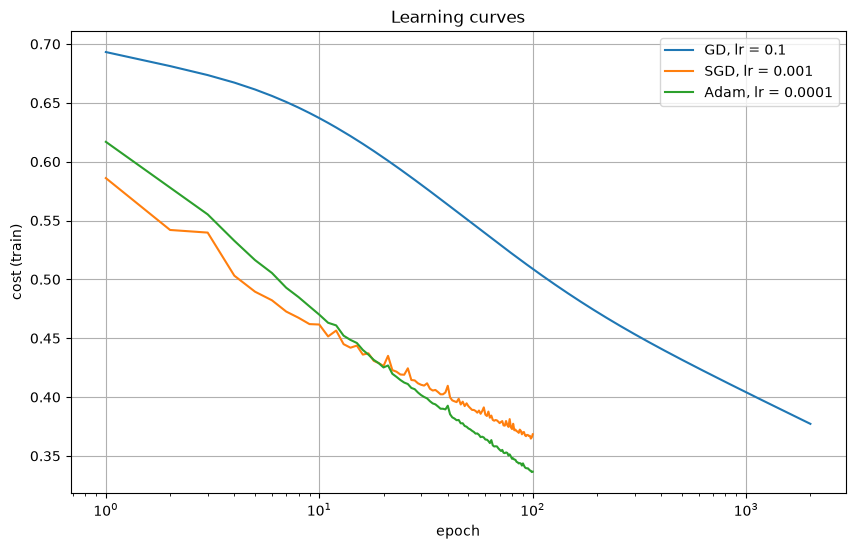

In [12]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(d_gd['costs']) + 1), d_gd['costs'], label='GD, lr = 0.1')
plt.plot(range(1, len(d_sgd['costs']) + 1), d_sgd['costs'], label='SGD, lr = 0.001')
plt.plot(range(1, len(d_adam['costs']) + 1), d_adam['costs'], label='Adam, lr = 0.0001')
plt.xscale('log')
plt.xlabel('epoch')
plt.ylabel('cost (train)')
plt.title('Learning curves')
plt.grid(True)
plt.legend()
plt.show()

### 5. Different learning rates

5 values of the learning rate for each method. For GD 2000 iterations, for SGD and Adam 100 epochs.

In [13]:
learning_rates = {
    'gd': [0.001, 0.01, 0.1, 0.3, 1],
    'sgd': [0.0001, 0.001, 0.01, 0.1, 1],
    'adam': [0.00001, 0.0001, 0.001, 0.01, 0.1],
}
n_iter = {'gd': 2000, 'sgd': 100, 'adam': 100}

lr_models = {}
for opt in ['gd', 'sgd', 'adam']:
    for lr in learning_rates[opt]:
        lr_models[(opt, lr)] = model(X_train, Y_train, X_test, Y_test, optimizer=opt,
                                     num_iterations=n_iter[opt], learning_rate=lr)

gd, lr = 0.001: train accuracy: 73.16, test accuracy: 71.96


gd, lr = 0.01: train accuracy: 78.99, test accuracy: 76.23


gd, lr = 0.1: train accuracy: 84.18, test accuracy: 76.76


gd, lr = 0.3: train accuracy: 85.53, test accuracy: 75.69


gd, lr = 1: train accuracy: 83.19, test accuracy: 74.20


sgd, lr = 0.0001: train accuracy: 79.88, test accuracy: 77.08


... (6 outputs left out)

adam, lr = 0.0001: train accuracy: 86.03, test accuracy: 76.76


adam, lr = 0.001: train accuracy: 91.25, test accuracy: 74.20


adam, lr = 0.01: train accuracy: 89.62, test accuracy: 71.75


adam, lr = 0.1: train accuracy: 87.38, test accuracy: 69.83


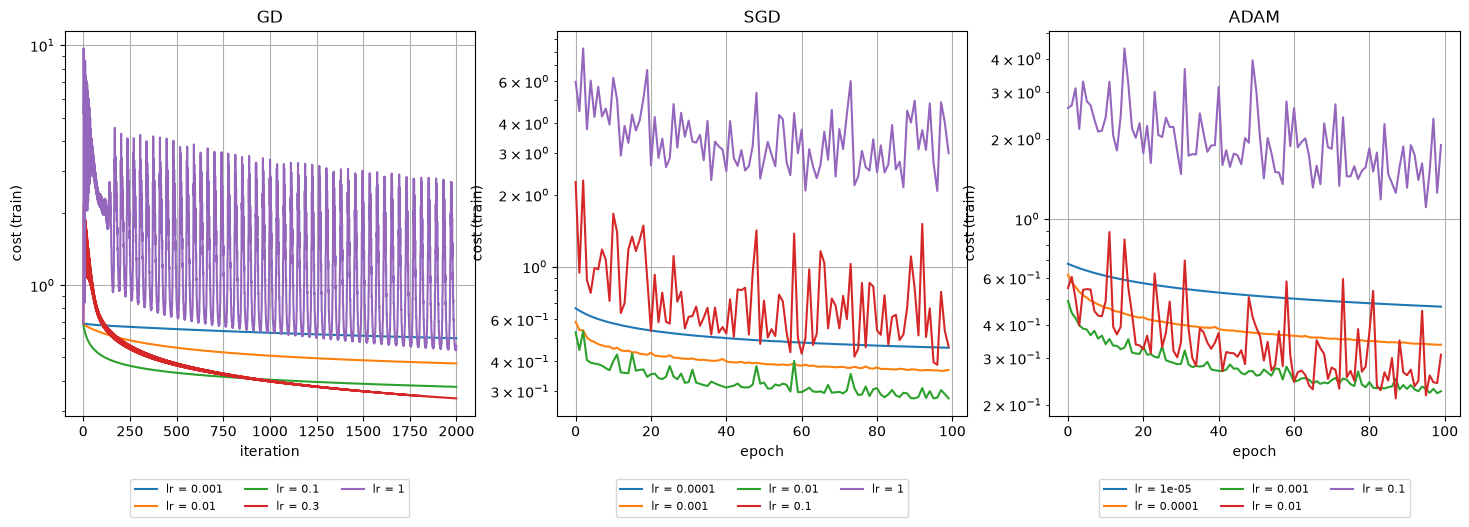

In [14]:
plt.figure(figsize=(18, 5))
for i, opt in enumerate(['gd', 'sgd', 'adam']):
    plt.subplot(1, 3, i + 1)
    for lr in learning_rates[opt]:
        plt.plot(lr_models[(opt, lr)]['costs'], label='lr = {}'.format(lr))
    plt.yscale('log')
    plt.xlabel('iteration' if opt == 'gd' else 'epoch')
    plt.ylabel('cost (train)')
    plt.title(opt.upper())
    plt.grid(True)
    plt.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
plt.show()

GD with big learning rates oscillates, here are the first 50 iterations:

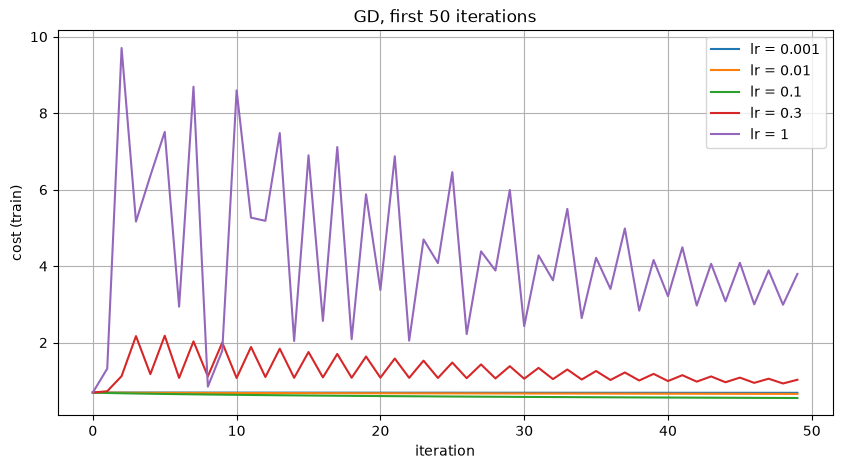

In [15]:
plt.figure(figsize=(10, 5))
for lr in learning_rates['gd']:
    plt.plot(lr_models[('gd', lr)]['costs'][:50], label='lr = {}'.format(lr))
plt.xlabel('iteration')
plt.ylabel('cost (train)')
plt.title('GD, first 50 iterations')
plt.grid(True)
plt.legend()
plt.show()

In [16]:
lr_table = pd.DataFrame([
    {'optimizer': opt.upper(), 'learning rate': lr,
     'train accuracy': d['train_accuracy'], 'test accuracy': d['test_accuracy'],
     'final train cost': d['costs'][-1], 'test cost': d['test_cost']}
    for (opt, lr), d in lr_models.items()
])
lr_table.round({'train accuracy': 2, 'test accuracy': 2, 'final train cost': 3, 'test cost': 3})

,optimizer,learning rate,train accuracy,test accuracy,final train cost,test cost
0,GD,0.00100,73.16,71.96,0.601,0.601
1,GD,0.01000,78.99,76.23,0.472,0.509
2,GD,0.10000,84.18,76.76,0.377,0.509
3,GD,0.30000,85.53,75.69,0.338,0.561
4,GD,1.00000,83.19,74.20,0.559,1.333
5,SGD,0.00010,79.88,77.08,0.456,0.503
6,SGD,0.00100,84.18,76.65,0.368,0.529
7,SGD,0.01000,89.05,75.16,0.280,0.686
8,SGD,0.10000,87.56,72.92,0.462,2.205
9,SGD,1.00000,83.47,71.64,2.994,5.943


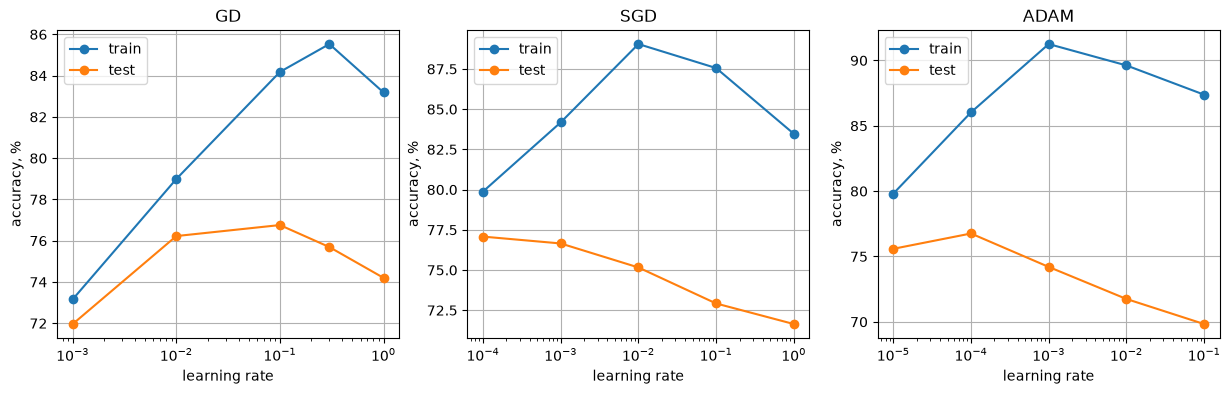

In [17]:
plt.figure(figsize=(15, 4))
for i, opt in enumerate(['gd', 'sgd', 'adam']):
    t = lr_table[lr_table.optimizer == opt.upper()]
    plt.subplot(1, 3, i + 1)
    plt.plot(t['learning rate'], t['train accuracy'], marker='o', label='train')
    plt.plot(t['learning rate'], t['test accuracy'], marker='o', label='test')
    plt.xscale('log')
    plt.xlabel('learning rate')
    plt.ylabel('accuracy, %')
    plt.title(opt.upper())
    plt.grid(True)
    plt.legend()
plt.show()

### 6. Conclusions

1. Accuracy. All three methods give almost the same test accuracy: GD 76.76%, SGD 76.65%, Adam 76.76% (the difference is 1 object of 938). This is expected: the cost of logistic regression is convex, so all methods go to the same minimum, they only reach it differently.

2. Speed. GD needs 2000 iterations (2000 passes through the data) to get the train cost 0.377. SGD gets the same cost after about 80 epochs and Adam after about 45, because in one epoch they make 2813 updates and GD makes only one. But in time the difference is small here: one GD iteration is a single matrix multiplication in numpy, and SGD / Adam go object by object in a python loop.

3. Learning curves. The GD curve is smooth. The SGD curve is noisy (sometimes the cost goes up), because every step uses only one object and the gradient is not exact. Adam is smoother than SGD and goes lower (0.337 vs 0.368 after 100 epochs), because of the momentum and the separate step size for every weight.

4. Learning rate.
   - too small - the model learns too slowly: GD with lr = 0.001 after 2000 iterations still has cost 0.60 and test accuracy only 72%
   - too big - the cost oscillates and does not go down: GD with lr = 0.3 and 1 jumps up every second iteration, SGD with lr = 1 and Adam with lr = 0.1 have cost 2-3 and test accuracy 70-72%
   - good values: GD 0.01 - 0.1, SGD 0.0001 - 0.001, Adam 0.0001 (test accuracy 76-77%)
   - Adam needs a much smaller lr than GD, because its step is divided by sqrt(S): every weight moves by about lr on each update, no matter how big the gradient is.

5. Overfitting. There is no regularization and we have 1776 features for 2813 objects, so a smaller train cost does not mean a better model. For example Adam with lr = 0.001 has 91.3% on train but only 74.2% on test. The best test accuracy (77.08%) is SGD with the smallest lr = 0.0001, which did not have time to overfit. To improve it we could add L2 regularization or stop earlier (early stopping on a validation set).

Note: here the learning rates were compared on the test set. To choose the learning rate honestly it is better to use a separate validation set and check only the final model on the test.